In [3]:
#Members within the group are homogenous
#and members between the group are heterogenous
# ------------------------------------------------------------
# 1. IMPORT LIBRARIES
# ------------------------------------------------------------
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

from sklearn.cluster import AgglomerativeClustering
from sklearn.cluster import SpectralClustering

from sklearn.metrics import silhouette_score
from sklearn.metrics import adjusted_rand_score

from scipy.cluster.hierarchy import dendrogram, linkage

In [4]:
# ------------------------------------------------------------
# 2. LOAD BUILT-IN WINE DATASET
# ------------------------------------------------------------
wine = load_wine()
df = pd.DataFrame(wine.data, columns=wine.feature_names)

# Add original wine category for evaluation only
df['Original_Class'] = wine.target

print("\nFirst five records:")
df.head()


First five records:


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,Original_Class
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


In [5]:
# ------------------------------------------------------------
# 3. EXPLORATORY DATA ANALYSIS (EDA)
# ------------------------------------------------------------
print("\nDataset Information:")
print(df.info())


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 14 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   alcohol                       178 non-null    float64
 1   malic_acid                    178 non-null    float64
 2   ash                           178 non-null    float64
 3   alcalinity_of_ash             178 non-null    float64
 4   magnesium                     178 non-null    float64
 5   total_phenols                 178 non-null    float64
 6   flavanoids                    178 non-null    float64
 7   nonflavanoid_phenols          178 non-null    float64
 8   proanthocyanins               178 non-null    float64
 9   color_intensity               178 non-null    float64
 10  hue                           178 non-null    float64
 11  od280/od315_of_diluted_wines  178 non-null    float64
 12  proline                       178 non-null

In [6]:
print("\nStatistical Summary:")
print(df.describe())


Statistical Summary:
          alcohol  malic_acid         ash  alcalinity_of_ash   magnesium  \
count  178.000000  178.000000  178.000000         178.000000  178.000000   
mean    13.000618    2.336348    2.366517          19.494944   99.741573   
std      0.811827    1.117146    0.274344           3.339564   14.282484   
min     11.030000    0.740000    1.360000          10.600000   70.000000   
25%     12.362500    1.602500    2.210000          17.200000   88.000000   
50%     13.050000    1.865000    2.360000          19.500000   98.000000   
75%     13.677500    3.082500    2.557500          21.500000  107.000000   
max     14.830000    5.800000    3.230000          30.000000  162.000000   

       total_phenols  flavanoids  nonflavanoid_phenols  proanthocyanins  \
count     178.000000  178.000000            178.000000       178.000000   
mean        2.295112    2.029270              0.361854         1.590899   
std         0.625851    0.998859              0.124453         0.572

In [7]:
print("\nMissing Values:")
print(df.isnull().sum())


Missing Values:
alcohol                         0
malic_acid                      0
ash                             0
alcalinity_of_ash               0
magnesium                       0
total_phenols                   0
flavanoids                      0
nonflavanoid_phenols            0
proanthocyanins                 0
color_intensity                 0
hue                             0
od280/od315_of_diluted_wines    0
proline                         0
Original_Class                  0
dtype: int64


In [8]:
print("\nDuplicate Records:")
print(df.duplicated().sum())


Duplicate Records:
0


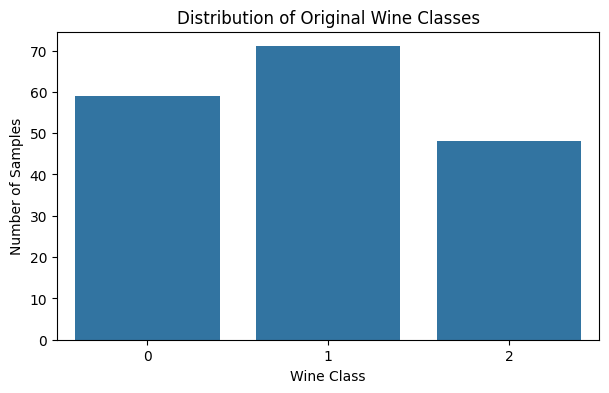

In [9]:
# ------------------------------------------------------------
# 4. CHECK ORIGINAL CLASS DISTRIBUTION
# ------------------------------------------------------------
plt.figure(figsize=(7, 4))
sns.countplot(data=df, x='Original_Class')
plt.title("Distribution of Original Wine Classes")
plt.xlabel("Wine Class")
plt.ylabel("Number of Samples")
plt.show()

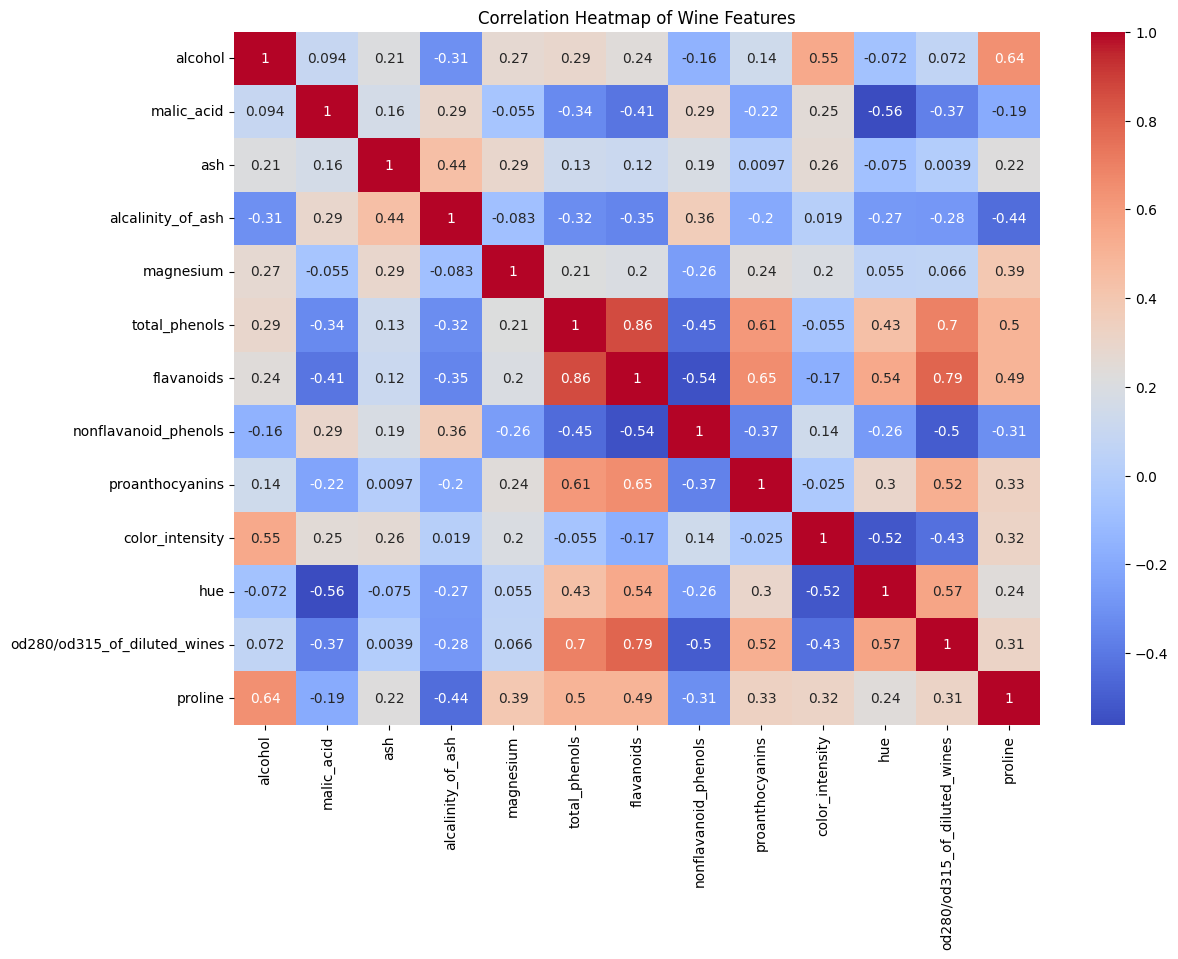

In [10]:
# ------------------------------------------------------------
# 5. CORRELATION HEATMAP
# ------------------------------------------------------------
plt.figure(figsize=(13, 9))

sns.heatmap(
    df.drop(columns='Original_Class').corr(),
    cmap='coolwarm',
    annot=True
)

plt.title("Correlation Heatmap of Wine Features")
plt.show()

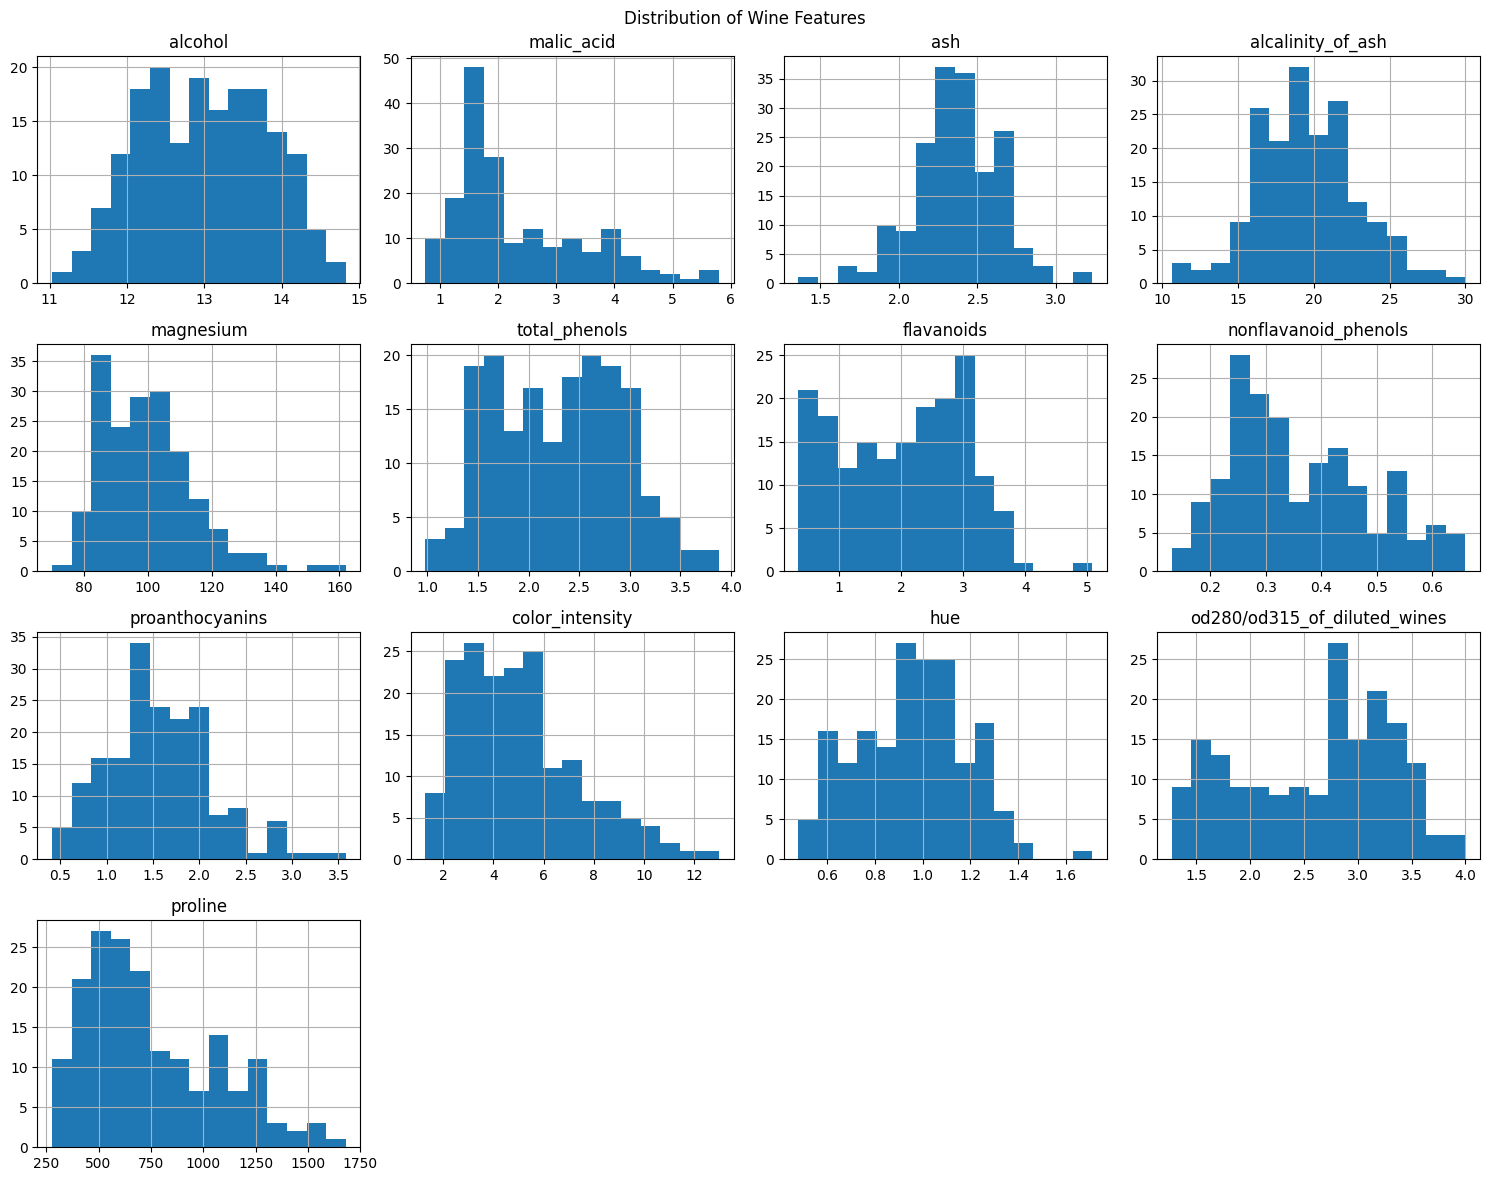

In [11]:
# ------------------------------------------------------------
# 6. DISTRIBUTION OF FEATURES
# ------------------------------------------------------------
df.drop(columns='Original_Class').hist(
    figsize=(15, 12),
    bins=15
)

plt.suptitle("Distribution of Wine Features")
plt.tight_layout()
plt.show()


In [12]:
# ------------------------------------------------------------
# 7. SELECT FEATURES
# ------------------------------------------------------------
X = df.drop(columns='Original_Class')
y = df['Original_Class']
print("Number of features:", X.shape[1])

Number of features: 13


In [13]:
# ------------------------------------------------------------
# 8. FEATURE SCALING
# ------------------------------------------------------------
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print("\nFeature scaling completed")


Feature scaling completed


Explained Variance: [0.36198848 0.1920749 ]


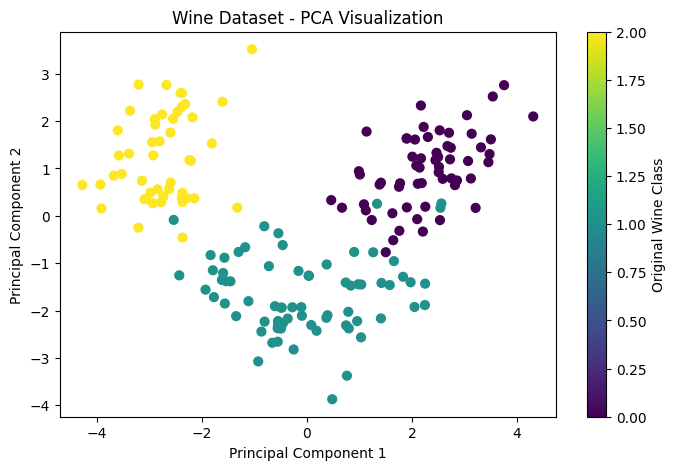

In [14]:
# ------------------------------------------------------------
# 9. PCA FOR 2D VISUALIZATION
# ------------------------------------------------------------
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)
print("Explained Variance:", pca.explained_variance_ratio_)

plt.figure(figsize=(8, 5))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=y,
    cmap='viridis',
    s=40
)

plt.title("Wine Dataset - PCA Visualization")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.colorbar(label="Original Wine Class")
plt.show()

In [15]:
# ============================================================
# 10. HIERARCHICAL CLUSTERING
# ============================================================
# Create linkage matrix using Ward method
linked = linkage(
    X_scaled,
    method='ward'
)

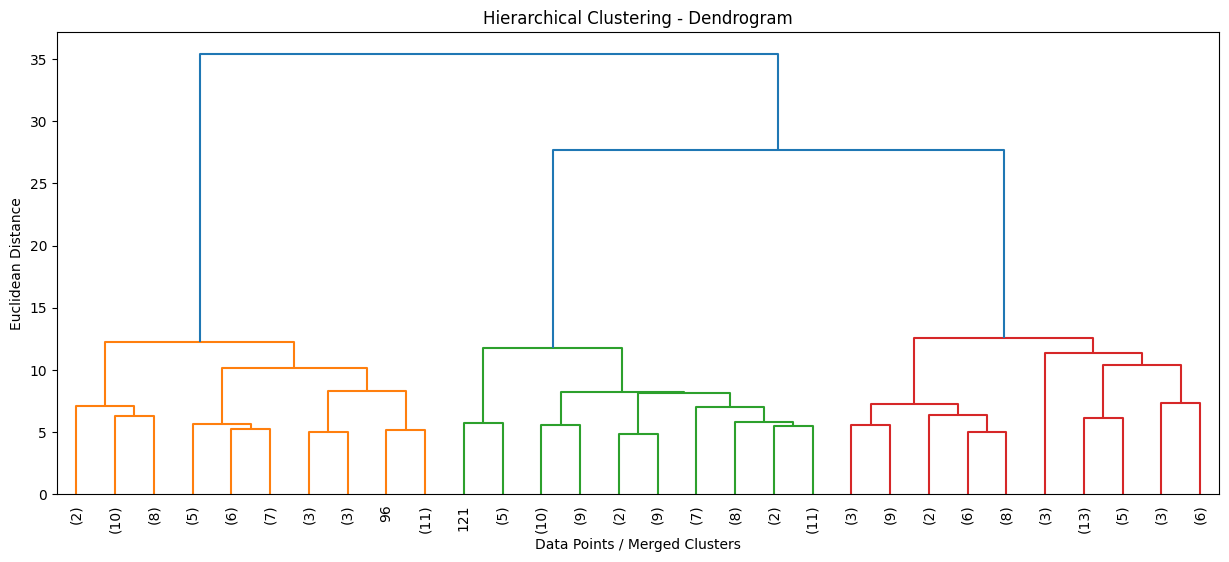

In [16]:
# ------------------------------------------------------------
# 11. DENDROGRAM VISUALIZATION
# ------------------------------------------------------------
plt.figure(figsize=(15, 6))

dendrogram(
    linked,
    truncate_mode='lastp',
    p=30,
    leaf_rotation=90,
    leaf_font_size=10
)
plt.title("Hierarchical Clustering - Dendrogram")
plt.xlabel("Data Points / Merged Clusters")
plt.ylabel("Euclidean Distance")
plt.show()

In [17]:
# ------------------------------------------------------------
# 12. AGGLOMERATIVE CLUSTERING-Join
# ------------------------------------------------------------
hc = AgglomerativeClustering(
    n_clusters=3,
    linkage='ward'
)
hierarchical_labels = hc.fit_predict(X_scaled)
df['Hierarchical_Cluster'] = hierarchical_labels
print("\nHierarchical Cluster Counts:")
print(df['Hierarchical_Cluster'].value_counts().sort_index())


Hierarchical Cluster Counts:
Hierarchical_Cluster
0    58
1    56
2    64
Name: count, dtype: int64


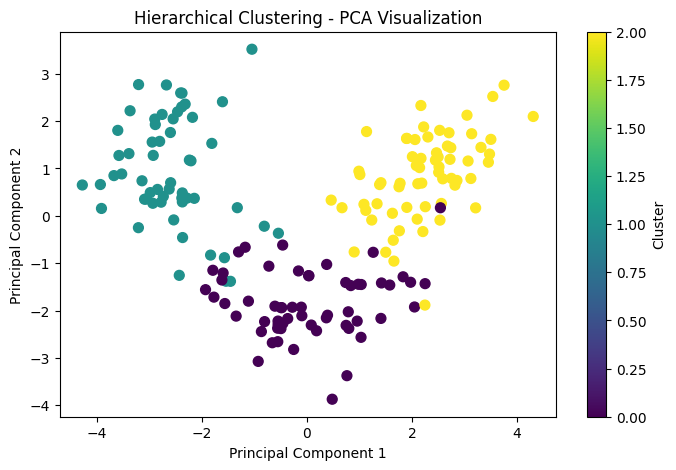

In [18]:
# ------------------------------------------------------------
# 13. VISUALIZE HIERARCHICAL CLUSTERS
# ------------------------------------------------------------
plt.figure(figsize=(8, 5))
plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=hierarchical_labels,
    cmap='viridis',
    s=50
)
plt.title("Hierarchical Clustering - PCA Visualization")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.colorbar(label="Cluster")
plt.show()

**Spectral Clustering**

In [19]:
# ============================================================
# 14. SPECTRAL CLUSTERING
# ============================================================
spectral = SpectralClustering(
    n_clusters=3,
    affinity='nearest_neighbors',
    n_neighbors=10,
    assign_labels='kmeans',
    random_state=42
)

spectral_labels = spectral.fit_predict(X_scaled)

df['Spectral_Cluster'] = spectral_labels

print("\nSpectral Cluster Counts:")
print(df['Spectral_Cluster'].value_counts().sort_index())




Spectral Cluster Counts:
Spectral_Cluster
0    51
1    63
2    64
Name: count, dtype: int64


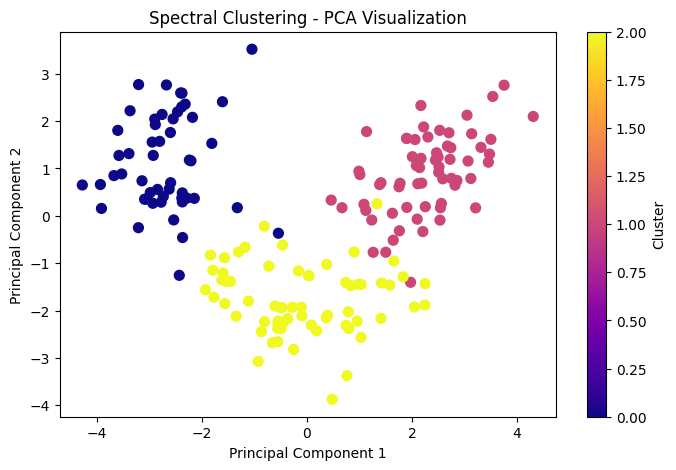

In [20]:
# ------------------------------------------------------------
# 15. VISUALIZE SPECTRAL CLUSTERS
# ------------------------------------------------------------

plt.figure(figsize=(8, 5))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=spectral_labels,
    cmap='plasma',
    s=50
)

plt.title("Spectral Clustering - PCA Visualization")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.colorbar(label="Cluster")
plt.show()




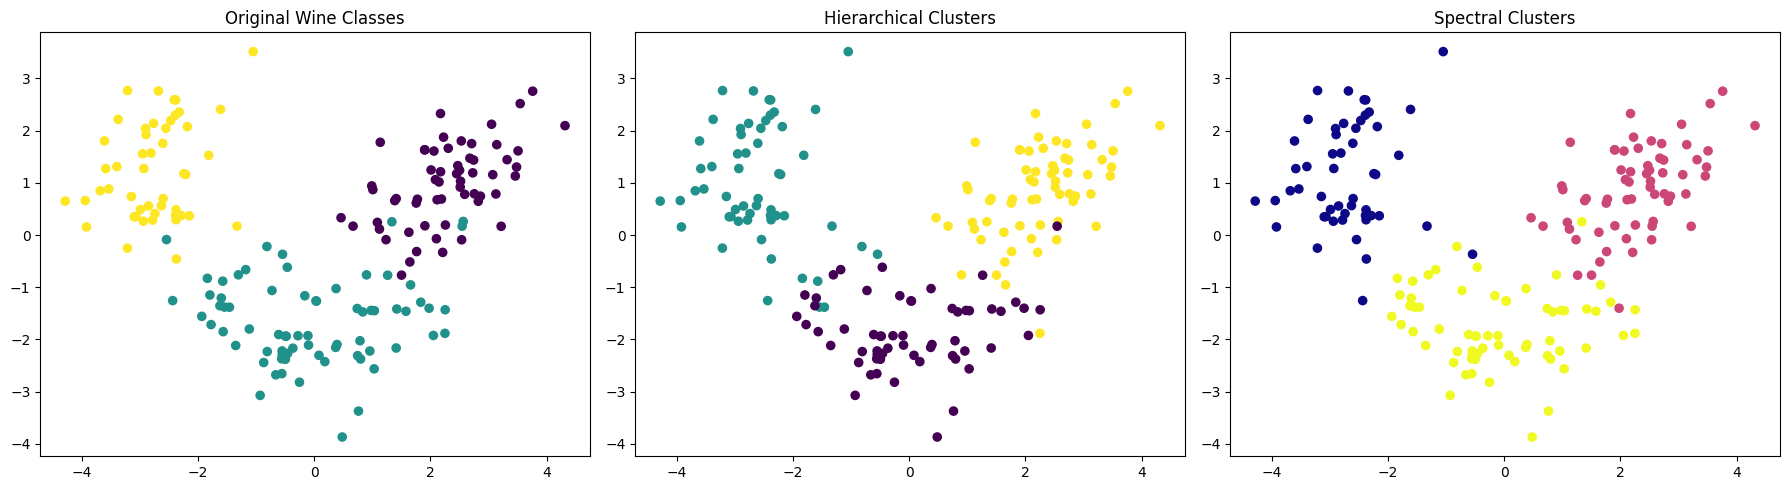

In [21]:
# ============================================================
# 16. COMPARE ORIGINAL AND PREDICTED CLUSTERS
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].scatter(
    X_pca[:, 0], X_pca[:, 1],
    c=y, cmap='viridis', s=35
)

axes[0].set_title("Original Wine Classes")

axes[1].scatter(
    X_pca[:, 0], X_pca[:, 1],
    c=hierarchical_labels, cmap='viridis', s=35
)

axes[1].set_title("Hierarchical Clusters")

axes[2].scatter(
    X_pca[:, 0], X_pca[:, 1],
    c=spectral_labels, cmap='plasma', s=35
)

axes[2].set_title("Spectral Clusters")

plt.tight_layout()
plt.show()



In [22]:
# ------------------------------------------------------------
# 17. EVALUATE CLUSTERING PERFORMANCE
# ------------------------------------------------------------

# Silhouette Score
# Higher value generally indicates better-separated clusters

hierarchical_silhouette = silhouette_score(
    X_scaled,
    hierarchical_labels
)

spectral_silhouette = silhouette_score(
    X_scaled,
    spectral_labels
)


# Adjusted Rand Index
# Compares predicted clusters with original wine classes

hierarchical_ari = adjusted_rand_score(
    y,
    hierarchical_labels
)

spectral_ari = adjusted_rand_score(
    y,
    spectral_labels
)

In [23]:
# ------------------------------------------------------------
# 18. FINAL PERFORMANCE COMPARISON
# ------------------------------------------------------------

results = pd.DataFrame({
    'Algorithm': [
        'Hierarchical Clustering',
        'Spectral Clustering'
    ],

    'Silhouette Score': [
        hierarchical_silhouette,
        spectral_silhouette
    ],

    'Adjusted Rand Index': [
        hierarchical_ari,
        spectral_ari
    ]
})

print("\nFINAL CLUSTERING COMPARISON")

print(results.round(4))




FINAL CLUSTERING COMPARISON
                 Algorithm  Silhouette Score  Adjusted Rand Index
0  Hierarchical Clustering            0.2774               0.7899
1      Spectral Clustering            0.2828               0.8804
